# Assignment 3 – Model Evaluation
## Part 1

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

### 1. Load and check sleep.csv

In [43]:
df = pd.read_csv('sleep.csv')
display(df.head().T)

,0,1,2,3,4
user_id,USR-00001,USR-00002,USR-00003,USR-00004,USR-00005
age,29,58,41,36,23
gender,Female,Female,Female,Non-Binary,Female
occupation_type,Healthcare / Shift Worker,Student,Healthcare / Shift Worker,Remote Tech,Healthcare / Shift Worker
chronotype,Intermediate,Intermediate,Night Owl,Intermediate,Intermediate
bedtime_phone_minutes,179,163,100,34,27
primary_bedtime_app,Instagram / Reddit,YouTube,TikTok / Reels,YouTube,TikTok / Reels
screen_brightness_pct,54,76,59,52,82
blue_light_filter_active,1,1,0,0,1
caffeine_post_5pm_mg,0,92,45,97,0


In [44]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,8500.0,34.36,11.58,18.0,25.00,32.00,42.00,65.0
bedtime_phone_minutes,8500.0,59.25,36.93,1.0,31.00,51.00,79.00,180.0
screen_brightness_pct,8500.0,55.15,19.85,10.0,42.00,55.00,69.00,100.0
blue_light_filter_active,8500.0,0.47,0.50,0.0,0.00,0.00,1.00,1.0
caffeine_post_5pm_mg,8500.0,33.22,51.94,0.0,0.00,0.00,55.00,250.0
physical_activity_min,8500.0,35.70,20.82,0.0,21.00,35.00,50.00,112.0
sleep_latency_min,8500.0,40.67,17.44,6.0,28.20,37.60,49.70,123.3
total_sleep_hours,8500.0,6.27,1.45,3.2,5.24,6.33,7.35,9.8
deep_sleep_pct,8500.0,21.74,3.07,8.1,19.70,21.90,23.90,28.0
rem_sleep_pct,8500.0,19.11,2.55,9.6,17.40,19.10,20.80,27.0


### Split columns to numerical and categorical

In [45]:
all = df.columns.tolist()
print(f'All numerical columns[{len(all)}]: {all}')

numerical = [
    'age',
    'bedtime_phone_minutes',
    'screen_brightness_pct',
    'caffeine_post_5pm_mg',
    'physical_activity_min',
    'sleep_latency_min',
    'total_sleep_hours',
    'deep_sleep_pct',
    'rem_sleep_pct',
    'next_day_fatigue_score',
    'morning_alarm_snoozes'
]
print(f'Numerical columns[{len(numerical)}]: {numerical}')

categorical = [
    'gender',
    'occupation_type',
    'chronotype',
    'primary_bedtime_app',
    'sleep_debt_category',
    'blue_light_filter_active'
]
print(f'Categorical columns[{len(categorical)}]: {categorical}')

All numerical columns[18]: ['user_id', 'age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score', 'sleep_debt_category']
Numerical columns[11]: ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'next_day_fatigue_score', 'morning_alarm_snoozes']
Categorical columns[6]: ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app', 'sleep_debt_category', 'blue_light_filter_active']


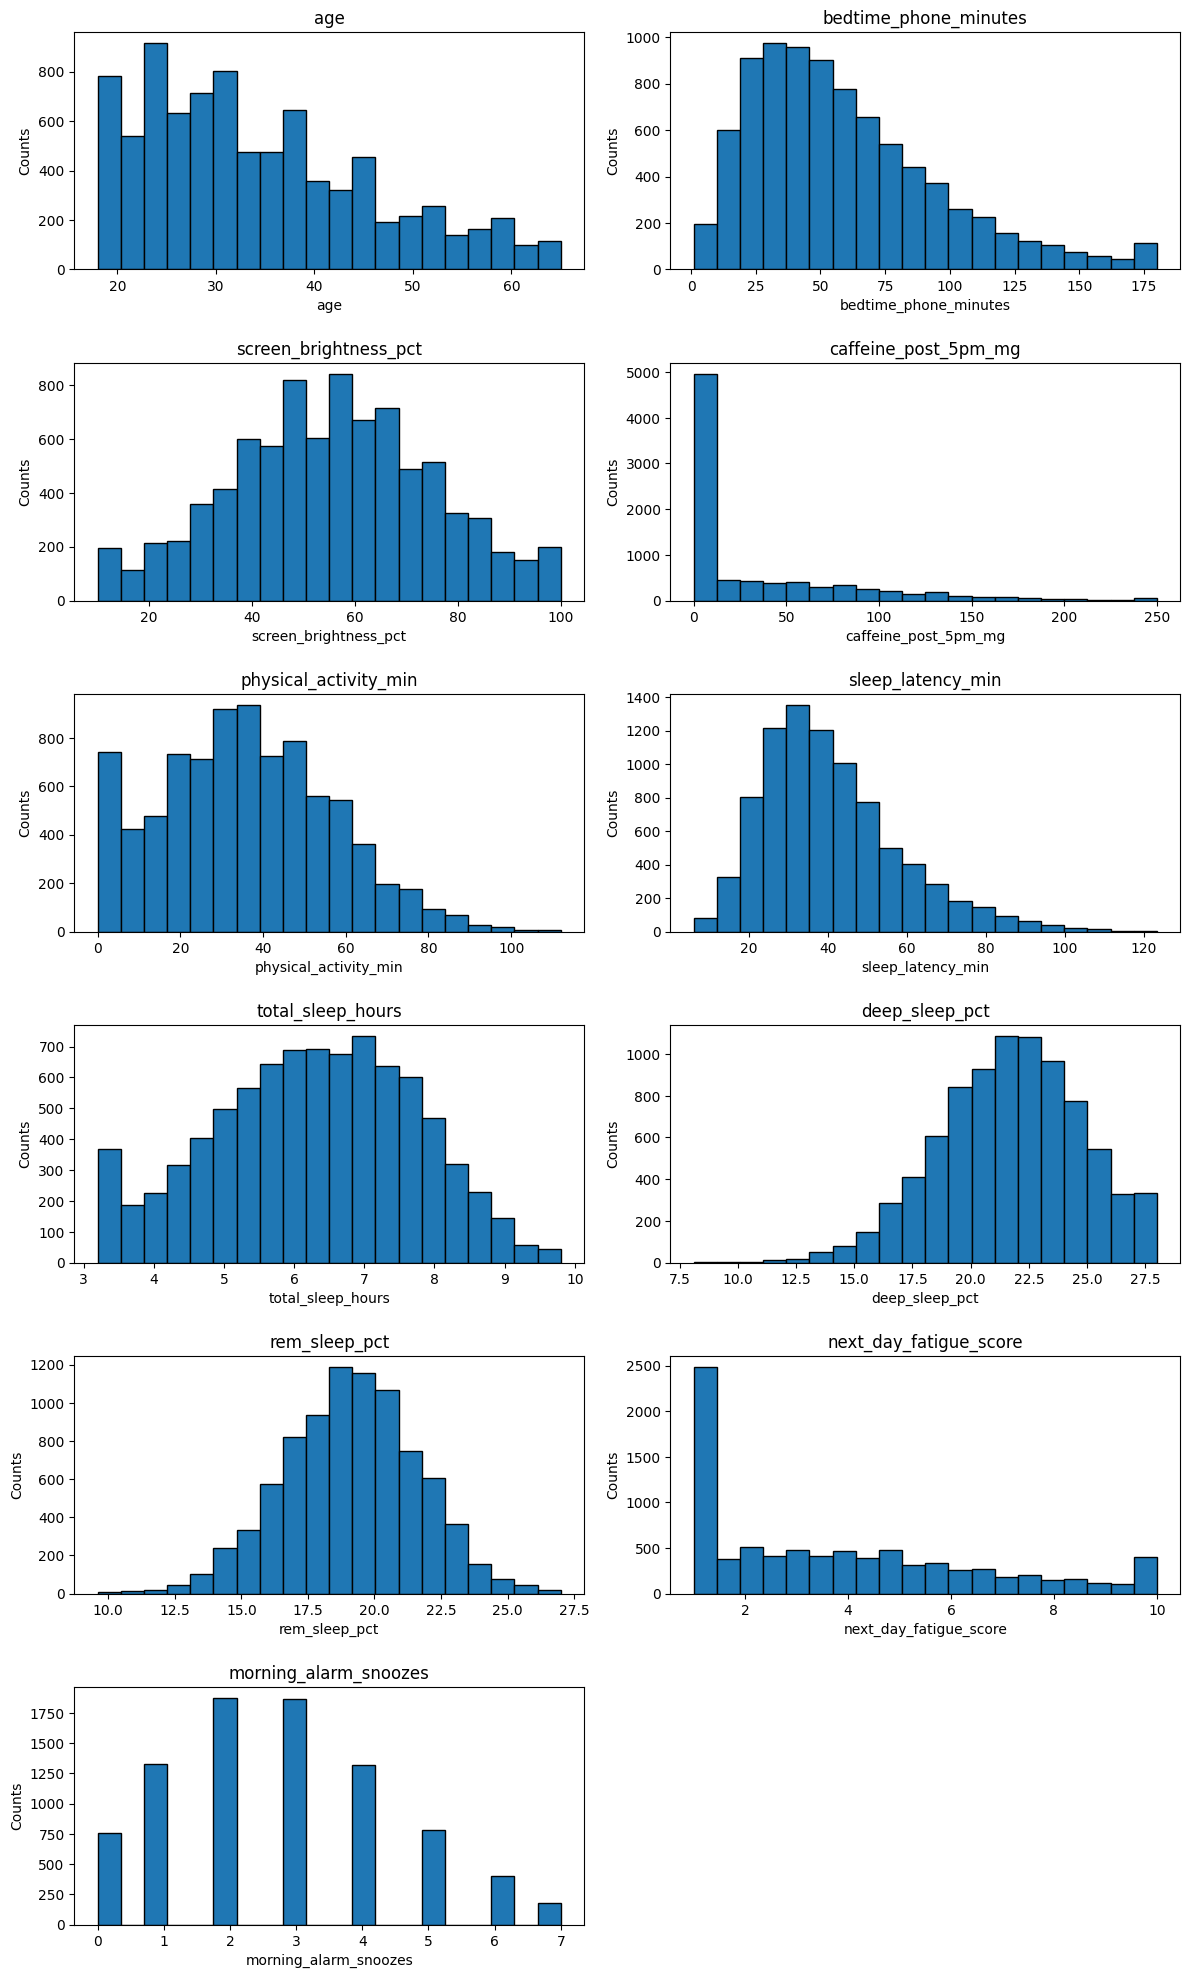

In [46]:
hvars = df[numerical]
fig, axes = plt.subplots(len(hvars.columns) , 2, figsize=(12, 36))
axes = axes.flatten()

for i, col in enumerate(hvars):
  axes[i].hist(hvars[col], bins=20, edgecolor='black')
  axes[i].set_title(col)
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Counts')

for i in range(len(hvars.columns), len(axes)):
  axes[i].set_visible(False)

plt.tight_layout(h_pad=2)
plt.show()

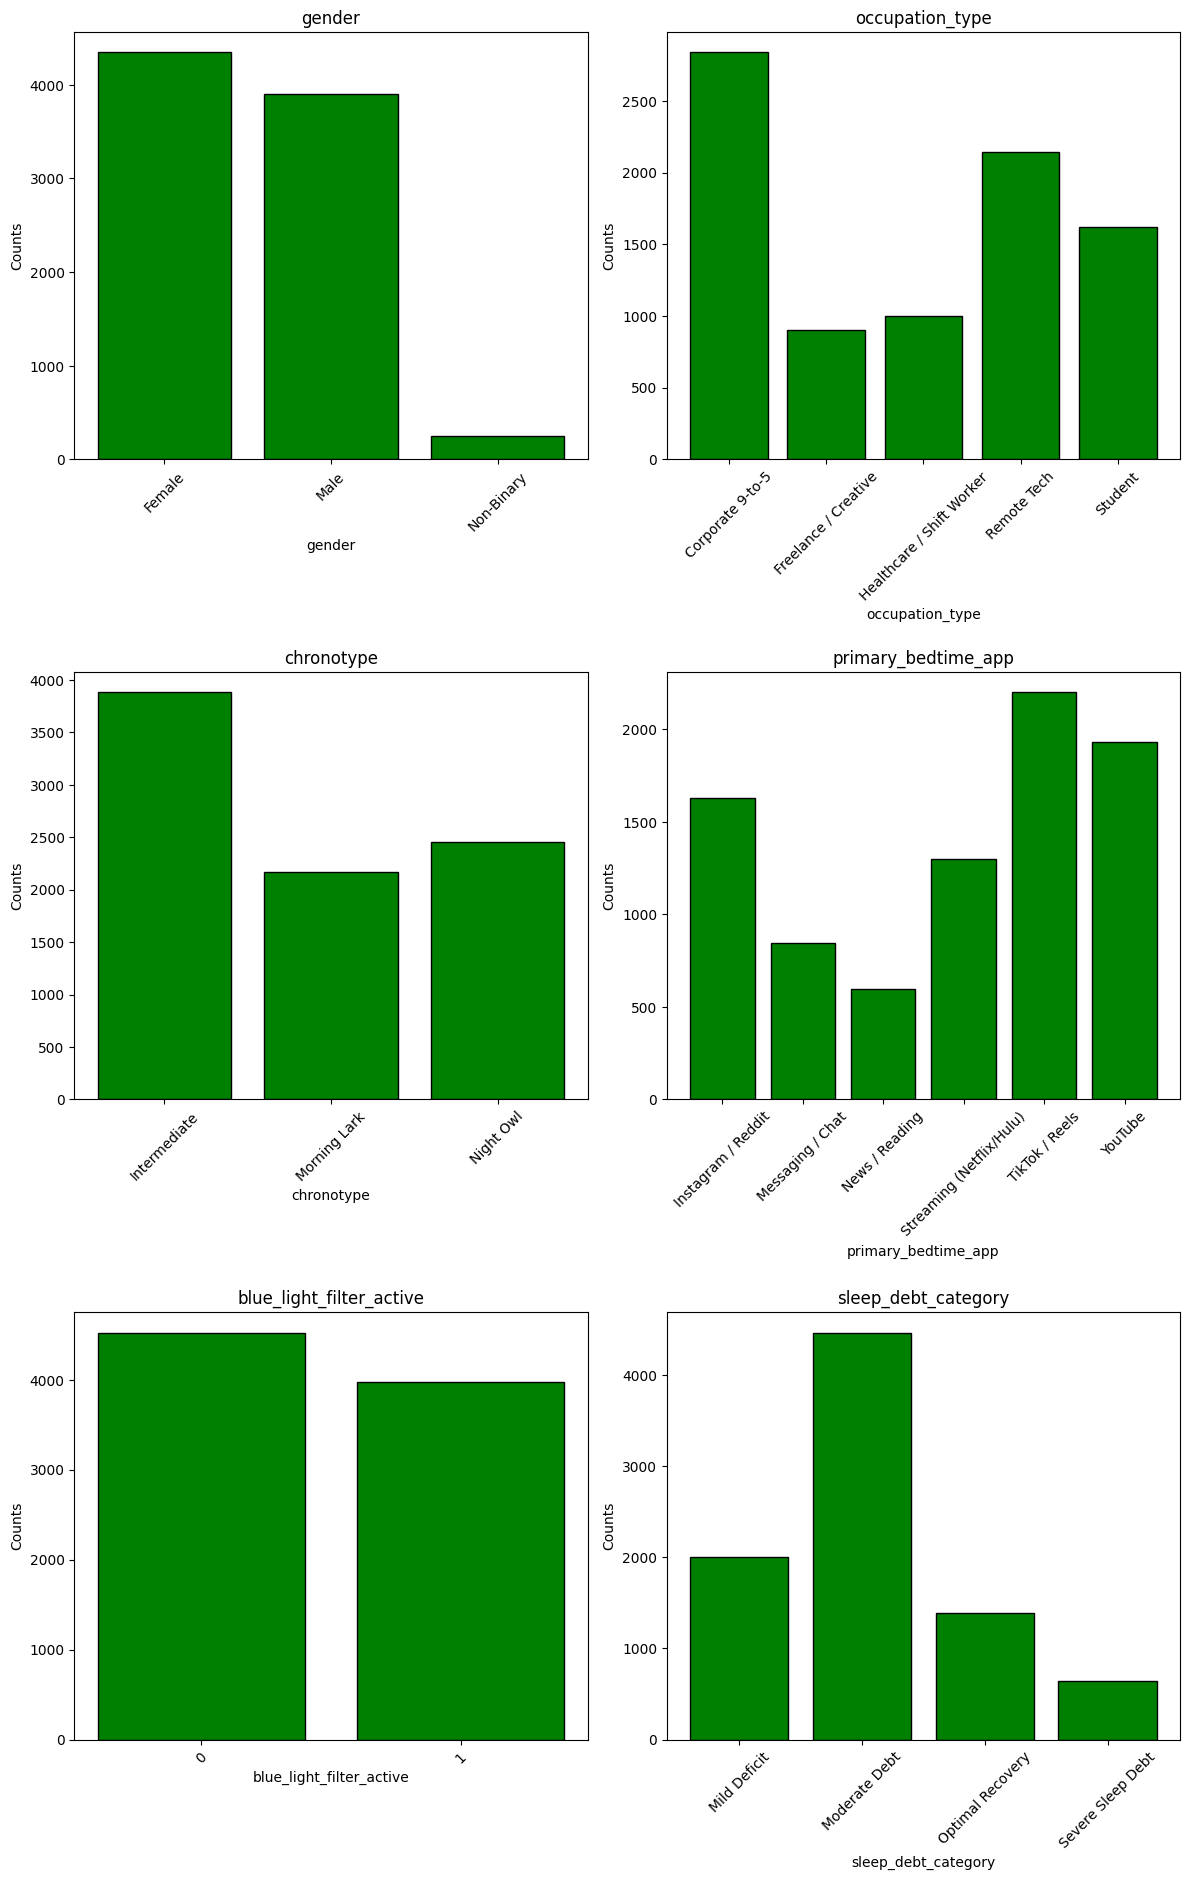

In [47]:
bvars = df.drop(columns=['user_id'] + numerical)
fig, axes = plt.subplots(4, 2, figsize=(12, 24))
axes = axes.flatten()

for i, col in enumerate(bvars.columns):
  counts = bvars[col].value_counts().sort_index()

  axes[i].bar(
      counts.index.astype(str),
      counts.values,
      edgecolor='black',
      color='green'
  )
  axes[i].set_title(col)
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Counts')
  axes[i].tick_params(axis='x', rotation=45)

for i in range(len(bvars.columns), len(axes)):
  axes[i].set_visible(False)

plt.tight_layout(h_pad=2)
plt.show()


In [48]:
counts = df['sleep_debt_category'].value_counts()

sleep = pd.DataFrame({
    'Count': counts,
    'Percentage': (counts / counts.sum() * 100).round(2)
})

display(sleep)

,Count,Percentage
sleep_debt_category,,
Moderate Debt,4462,52.49
Mild Deficit,2004,23.58
Optimal Recovery,1387,16.32
Severe Sleep Debt,647,7.61


We can observe that the classification target is imbalanced as Moderate Debt belongs to 52.49% of the rows and 'Severe sleep Debt' contains only 7.61%.

### 2. Remove next_day_fatigue_score

In [49]:
data = df.drop(columns=['user_id', 'next_day_fatigue_score'])
display(data.head().T)

,0,1,2,3,4
age,29,58,41,36,23
gender,Female,Female,Female,Non-Binary,Female
occupation_type,Healthcare / Shift Worker,Student,Healthcare / Shift Worker,Remote Tech,Healthcare / Shift Worker
chronotype,Intermediate,Intermediate,Night Owl,Intermediate,Intermediate
bedtime_phone_minutes,179,163,100,34,27
primary_bedtime_app,Instagram / Reddit,YouTube,TikTok / Reels,YouTube,TikTok / Reels
screen_brightness_pct,54,76,59,52,82
blue_light_filter_active,1,1,0,0,1
caffeine_post_5pm_mg,0,92,45,97,0
physical_activity_min,21,72,23,49,38


### 3. One hot encoding

In [50]:
print(f'Shape: {data.shape[0], data.shape[1]}')
print(f'Missing Values: { data.isna().sum().sum() }\n')

categorical_inputs = [
    'gender',
    'occupation_type',
    'chronotype',
    'primary_bedtime_app'
]

df_encoded = pd.get_dummies(data,columns=categorical_inputs, drop_first=False, dtype=int)


display(pd.DataFrame(df_encoded))
print(f'Result: { len(df_encoded)}')

display(df_encoded.head().T)

Shape: (8500, 16)
Missing Values: 0



,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Student,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,0,1,0,0,1,0,0,0,0,0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,1,1,0,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,0,0,0,1,0,0,0,0,1,0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,0,1,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,61,18,61,1,60,74,21.0,5.57,26.5,18.1,...,0,0,0,1,0,0,0,1,0,0
8496,64,138,58,1,0,58,84.3,3.99,20.4,19.4,...,1,0,0,1,0,0,0,0,1,0
8497,34,56,56,0,94,33,40.6,7.58,17.4,20.7,...,0,1,0,0,0,0,0,1,0,0
8498,23,165,72,0,0,52,123.3,3.20,14.2,15.8,...,0,0,0,1,0,0,0,0,1,0


Result: 8500


,0,1,2,3,4
age,29,58,41,36,23
bedtime_phone_minutes,179,163,100,34,27
screen_brightness_pct,54,76,59,52,82
blue_light_filter_active,1,1,0,0,1
caffeine_post_5pm_mg,0,92,45,97,0
physical_activity_min,21,72,23,49,38
sleep_latency_min,84.4,86.7,70.5,38.1,32.3
total_sleep_hours,3.2,4.06,3.2,6.99,4.58
deep_sleep_pct,23.5,18.0,18.1,21.6,24.1
rem_sleep_pct,22.2,21.5,20.5,22.4,22.8


### 4. Convert DataFrame to Numpy arrays

In [51]:
targets_df = df_encoded.drop(columns=['sleep_debt_category'])

y = df_encoded['sleep_debt_category'].to_numpy()
x = targets_df.to_numpy()

print(f'Shape: {x.shape, y.shape}')

Shape: ((8500, 28), (8500,))


### Split Dataset to Train-Test

There are no missing values, so no rows need to be removed before the split.

The split uses 70% of the data for training 20% for validation and 10% for testing.
Seed: 0

Seed enables reproducibility

In [52]:
seed = 0
test_size = 0.1
dataset_size = 1 - test_size
validation_size = 0.2 / dataset_size

x_train_10, x_test, y_train_10, y_test = train_test_split(
    x,
    y,
    test_size=test_size,
    random_state=seed,
    stratify=y
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_10,
    y_train_10,
    test_size=validation_size,
    random_state=seed,
    stratify=y_train_10
)

print(f'Train: {x_train.shape, y_train.shape}')
print(f'Validation: {x_val.shape, y_val.shape}')
print(f'Test: {x_test.shape, y_test.shape}')


Train: ((5949, 28), (5949,))
Validation: ((1701, 28), (1701,))
Test: ((850, 28), (850,))


### 5. K-Nearest Neighbors Classifier

In [53]:
from sklearn.preprocessing import StandardScaler

In [54]:
feature_columns = targets_df.columns

nm = feature_columns.isin(numerical)

x_train_scaled = x_train.astype(float, copy=True)
x_test_scaled = x_test.astype(float, copy=True)
x_val_scaled = x_val.astype(float, copy=True)

scaler = StandardScaler()
x_train_scaled[:,nm] = scaler.fit_transform(x_train[:,nm])
x_test_scaled[:,nm] = scaler.transform(x_test[:,nm])
x_val_scaled[:,nm] = scaler.transform(x_val[:,nm])

In [55]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score

In [56]:
n = int(np.sqrt(len(x_train_scaled)))
ks = [3, 5, 15, 50, n]
ks_test = [3, 5]
weights = ['uniform', 'distance']

results = []

for k in ks:
  for weight in weights:
    knn = KNeighborsClassifier(n_neighbors=k, weights=weight)

    knn.fit(x_train_scaled, y_train)

    train_predictions = knn.predict(x_train_scaled)
    val_predictions = knn.predict(x_val_scaled)

    results.append({
        'k': k,
        'weight': weight,

        'train': accuracy_score(y_train, train_predictions),
        'train precision': precision_score(y_train, train_predictions, average='macro', zero_division=0),
        'train recall': recall_score(y_train, train_predictions, average='macro', zero_division=0),
        'train f1': f1_score(y_train, train_predictions, average='macro', zero_division=0),
        'train balanced accuracy': balanced_accuracy_score(y_train, train_predictions),

        'validation': accuracy_score(y_val, val_predictions),
        'validation precision': precision_score(y_val, val_predictions, average='macro', zero_division=0),
        'validation recall': recall_score(y_val, val_predictions, average='macro', zero_division=0),
        'validation f1': f1_score(y_val, val_predictions, average='macro', zero_division=0),
        'validation balanced accuracy': balanced_accuracy_score(y_val, val_predictions)

    })

results_df = pd.DataFrame(results)
display(results_df)

,k,weight,train,train precision,train recall,train f1,train balanced accuracy,validation,validation precision,validation recall,validation f1,validation balanced accuracy
0,3,uniform,0.883846,0.880645,0.846818,0.862164,0.846818,0.768959,0.748574,0.722115,0.733671,0.722115
1,3,distance,1.000000,1.000000,1.000000,1.000000,1.000000,0.763081,0.738645,0.715610,0.726326,0.715610
2,5,uniform,0.862162,0.866161,0.810814,0.834555,0.810814,0.787184,0.783248,0.734699,0.754682,0.734699
3,5,distance,1.000000,1.000000,1.000000,1.000000,1.000000,0.784245,0.775345,0.731176,0.750403,0.731176
4,15,uniform,0.840309,0.855063,0.767531,0.801292,0.767531,0.815403,0.814075,0.742004,0.769315,0.742004
5,15,distance,1.000000,1.000000,1.000000,1.000000,1.000000,0.815403,0.811940,0.743248,0.770254,0.743248
6,50,uniform,0.823668,0.852522,0.727616,0.770827,0.727616,0.825397,0.845055,0.742707,0.778983,0.742707
7,50,distance,1.000000,1.000000,1.000000,1.000000,1.000000,0.829512,0.847297,0.751088,0.786428,0.751088
8,77,uniform,0.819465,0.851244,0.716643,0.762040,0.716643,0.819518,0.847043,0.730176,0.770457,0.730176
9,77,distance,1.000000,1.000000,1.000000,1.000000,1.000000,0.823045,0.847318,0.735304,0.775056,0.735304


In [57]:
best_result = results_df.loc[results_df['validation balanced accuracy'].idxmax()]

print(f"Best k: {int(best_result['k'])}")
print(f"Best weight: {best_result['weight']}")
print(f"Balanced Accuracy: {best_result['validation balanced accuracy']}")

display(best_result)

Best k: 50
Best weight: distance
Balanced Accuracy: 0.7510877842140272


,7
k,50
weight,distance
train,1.0
train precision,1.0
train recall,1.0
train f1,1.0
train balanced accuracy,1.0
validation,0.829512
validation precision,0.847297
validation recall,0.751088


### 6. Train-validation merge

In [58]:
x_train_val = np.concatenate([x_train, x_val], axis=0)
y_train_val = np.concatenate([y_train, y_val])

x_train_val_scaled = x_train_val.astype(float, copy=True)
x_test_final_scaled = x_test.astype(float, copy=True)

final_scaler = StandardScaler()

x_train_val_scaled[:,nm] = final_scaler.fit_transform(x_train_val[:, nm])
x_test_final_scaled[:,nm] = final_scaler.transform(x_test[:,nm])

In [59]:
bestK = best_result['k']
bestWeight = best_result['weight']

comp_knn = KNeighborsClassifier(n_neighbors=int(bestK),weights=bestWeight)
comp_knn.fit(x_train_val_scaled,y_train_val)

test_predictions = comp_knn.predict(x_test_final_scaled)

In [60]:

print(f'accuracy_score[Train|Validation|Test]: {best_result["train"]} | {best_result["validation"]} | {accuracy_score(y_test, test_predictions)}')
print(f'precision_score[Train|Validation|Test]: {best_result["train precision"]} | {best_result["validation precision"]} | {precision_score(y_test, test_predictions,average="macro", zero_division=0)}')
print(f'recall_score[Train|Validation|Test]: {best_result["train recall"]} | {best_result["validation recall"]} | {recall_score(y_test, test_predictions,average="macro", zero_division=0)}')
print(f'f1_score[Train|Validation|Test]: {best_result["train f1"]} | {best_result["validation f1"]} | {f1_score(y_test, test_predictions,average="macro", zero_division=0)}')
print(f'balanced_accuracy_score[Train|Validation|Test]: {best_result["train balanced accuracy"]} | {best_result["validation balanced accuracy"]} | {balanced_accuracy_score(y_test, test_predictions)}')


accuracy_score[Train|Validation|Test]: 1.0 | 0.829512051734274 | 0.8117647058823529
precision_score[Train|Validation|Test]: 1.0 | 0.8472973107007375 | 0.8313652177479025
recall_score[Train|Validation|Test]: 1.0 | 0.7510877842140272 | 0.7297308765612553
f1_score[Train|Validation|Test]: 1.0 | 0.786428033740212 | 0.7668439991962266
balanced_accuracy_score[Train|Validation|Test]: 1.0 | 0.7510877842140272 | 0.7297308765612553


For this case, since we have imbalanced classes, we use balanced accuracy for the best params selection.
Precision, recall and f1 use macro averaging to give all the classes the same weight.

We can see that the model has perfect scores on the training set since every training point is its own closest point.
Validation and test scores are not as good.

Test scores are from the model trained on the combined train + validation set.

### 7. Cross validation

In [61]:
from sklearn.model_selection import StratifiedKFold
from scipy.stats import t

def do_metric(y_true, y_pred):
    return {
            'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'balanced accuracy': balanced_accuracy_score(y_true, y_pred)
        }

In [62]:

x_cv, x_cv_test, y_cv, y_cv_test = train_test_split(x, y,test_size=test_size,random_state=seed,stratify=y)
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=seed)

In [63]:
cv_results = []
cv_fold_details = {}

for k in ks:
  for weight in weights:
    folds = []

    for train_i, val_i in cv.split(x_cv, y_cv):
      x_fold_train, x_fold_val = x_cv[train_i], x_cv[val_i]
      y_fold_train, y_fold_val = y_cv[train_i], y_cv[val_i]

      cv_scaler = StandardScaler()

      x_fold_train_scaled = x_fold_train.astype(float, copy=True)
      x_fold_val_scaled = x_fold_val.astype(float, copy=True)

      x_fold_train_scaled[:, nm] = cv_scaler.fit_transform(x_fold_train[:,nm])
      x_fold_val_scaled[:, nm] = cv_scaler.transform(x_fold_val[:,nm])

      knn = KNeighborsClassifier(n_neighbors=k, weights=weight)
      knn.fit(x_fold_train_scaled,y_fold_train)

      fold_pred = knn.predict(x_fold_val_scaled)
      fold_metrics = do_metric(y_fold_val, fold_pred)
      folds.append(fold_metrics)

    mean_metrics = {
      m: np.mean([f[m] for f in folds]) for m in folds[0]
    }

    cv_fold_details[(k, weight)] = folds

    cv_results.append({
        'k': k,
        'weight': weight,

        'accuracy': mean_metrics['accuracy'],
        'precision': mean_metrics['precision'],
        'recall': mean_metrics['recall'],
        'f1': mean_metrics['f1'],
        'balanced accuracy': mean_metrics['balanced accuracy']
    })

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df)

,k,weight,accuracy,precision,recall,f1,balanced accuracy
0,3,uniform,0.772418,0.762406,0.709852,0.731039,0.709852
1,3,distance,0.762614,0.747163,0.698638,0.719055,0.698638
2,5,uniform,0.788758,0.790222,0.722641,0.749355,0.722641
3,5,distance,0.780261,0.772929,0.713785,0.738179,0.713785
4,15,uniform,0.808758,0.820205,0.733516,0.765608,0.733516
5,15,distance,0.807582,0.814853,0.731658,0.763554,0.731658
6,50,uniform,0.813856,0.836935,0.717134,0.757708,0.717134
7,50,distance,0.814902,0.836799,0.722546,0.762332,0.722546
8,77,uniform,0.815817,0.845878,0.714850,0.758085,0.714850
9,77,distance,0.815948,0.843886,0.715669,0.758564,0.715669


In [64]:
best_cv_result = cv_results_df.loc[cv_results_df['balanced accuracy'].idxmax()]

print(f"Best k: {int(best_cv_result['k'])}")
print(f"Best weight: {best_cv_result['weight']}")
print(f"Balanced Accuracy: {best_cv_result['balanced accuracy']}")

display(best_cv_result)

Best k: 15
Best weight: uniform
Balanced Accuracy: 0.7335161922769367


,4
k,15
weight,uniform
accuracy,0.808758
precision,0.820205
recall,0.733516
f1,0.765608
balanced accuracy,0.733516


In [65]:
best_folds = cv_fold_details[(int(best_cv_result['k']), best_cv_result['weight'])]
num_folds = len(best_folds)

df_deg = num_folds - 1
confidence = 0.95
alpha = 1 - confidence
t_star = t.ppf(1 - alpha / 2, df_deg)

ci_records = []
for metric in ['accuracy', 'precision', 'recall', 'f1', 'balanced accuracy']:
  scores = [f[metric] for f in best_folds]

  mean_val = np.mean(scores)
  std_val = np.std(scores, ddof=1)
  error_margin = t_star * (std_val / np.sqrt(num_folds))

  ci_records.append({
      'Metric': metric,
      'Mean': round(mean_val, 4),
      'Std': round(std_val, 4),
      'Margin of error': round(error_margin, 4),
      '95pct confidence': f"[{mean_val - error_margin:.2f}, {mean_val + error_margin:.2f}]"
  })

ci_df = pd.DataFrame(ci_records)
display(ci_df)

,Metric,Mean,Std,Margin of error,95pct confidence
0,accuracy,0.8088,0.0132,0.0164,"[0.79, 0.83]"
1,precision,0.8202,0.0081,0.0101,"[0.81, 0.83]"
2,recall,0.7335,0.0214,0.0266,"[0.71, 0.76]"
3,f1,0.7656,0.0179,0.0222,"[0.74, 0.79]"
4,balanced accuracy,0.7335,0.0214,0.0266,"[0.71, 0.76]"


Mean/std of the 5 validation scores for the intervals (approximate due to overlap between training sets of folds and using the same folds to find the best parameters).

We train the best CV model with all training data and test on the test set.
Reset the scaler to only fit the training set.

In [66]:
x_cv_scaled = x_cv.astype(float, copy=True)
x_cv_test_scaled = x_cv_test.astype(float, copy=True)

cv_final_scaler = StandardScaler()
x_cv_scaled[:, nm] = cv_final_scaler.fit_transform(x_cv[:,nm])
x_cv_test_scaled[:, nm] = cv_final_scaler.transform(x_cv_test[:,nm])

cv_knn = KNeighborsClassifier(
    n_neighbors=int(best_cv_result['k']),
    weights=best_cv_result['weight']
)
cv_knn.fit(x_cv_scaled, y_cv)

cv_test_predictions = cv_knn.predict(x_cv_test_scaled)
cv_test_metrics = do_metric(y_cv_test, cv_test_predictions)

cv_comparison_df = pd.DataFrame([
    {
        'dataset': 'cv mean',
        'accuracy': best_cv_result['accuracy'],
        'precision': best_cv_result['precision'],
        'recall': best_cv_result['recall'],
        'f1': best_cv_result['f1'],
        'balanced accuracy': best_cv_result['balanced accuracy']
    },
    {
        'dataset': 'test',
        'accuracy': cv_test_metrics['accuracy'],
        'precision': cv_test_metrics['precision'],
        'recall': cv_test_metrics['recall'],
        'f1': cv_test_metrics['f1'],
        'balanced accuracy': cv_test_metrics['balanced accuracy']
    }
])

display(cv_comparison_df)

,dataset,accuracy,precision,recall,f1,balanced accuracy
0,cv mean,0.808758,0.820205,0.733516,0.765608,0.733516
1,test,0.804706,0.826809,0.733206,0.768604,0.733206


### 8. Nested cross validation

For each outer fold, we use 5 inner folds to select k and weight by mean balanced
accuracy. The scaler is fitted only on the training data of each inner fold.
We then fit a new scaler and the selected KNN on the complete outer training set
and evaluate on the outer validation set.

The outer loop uses all the data with 3 stratified folds. Each row is evaluated
once, and the outer validation data is not used to select the parameters.

In [67]:
out_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
in_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

ncv_results = []
ncv_inner_results = {}

for out_fold, (out_train_i, out_val_i) in enumerate(out_cv.split(x, y)):
    x_out_train, x_out_val = x[out_train_i], x[out_val_i]
    y_out_train, y_out_val = y[out_train_i], y[out_val_i]

    print(f"Outer Fold {out_fold + 1}:")
    print(f"Train: {x_out_train.shape, y_out_train.shape}")
    print(f"Validation: {x_out_val.shape, y_out_val.shape}\n")

    inner_results = []

    for k in ks:
        for weight in weights:
            folds = []

            for in_train_i, in_val_i in in_cv.split(x_out_train, y_out_train):
                x_in_train, x_in_val = x_out_train[in_train_i], x_out_train[in_val_i]
                y_in_train, y_in_val = y_out_train[in_train_i], y_out_train[in_val_i]

                x_in_train_scaled = x_in_train.astype(float, copy=True)
                x_in_val_scaled = x_in_val.astype(float, copy=True)

                inner_scaler = StandardScaler()
                x_in_train_scaled[:, nm] = inner_scaler.fit_transform(x_in_train[:,nm])
                x_in_val_scaled[:, nm] = inner_scaler.transform(x_in_val[:,nm])

                knn = KNeighborsClassifier(n_neighbors=k, weights=weight)
                knn.fit(x_in_train_scaled, y_in_train)

                inner_predictions = knn.predict(x_in_val_scaled)
                folds.append(do_metric(y_in_val, inner_predictions))

            mean_metrics = {
                m: np.mean([f[m] for f in folds]) for m in folds[0]
            }

            inner_results.append({
                'k': k,
                'weight': weight,
                'accuracy': mean_metrics['accuracy'],
                'precision': mean_metrics['precision'],
                'recall': mean_metrics['recall'],
                'f1': mean_metrics['f1'],
                'balanced accuracy': mean_metrics['balanced accuracy']
            })

    inner_results_df = pd.DataFrame(inner_results)
    ncv_inner_results[out_fold + 1] = inner_results_df
    best_inner_result = inner_results_df.loc[inner_results_df['balanced accuracy'].idxmax()]

    display(inner_results_df)
    print(f"Best k: {int(best_inner_result['k'])}")
    print(f"Best weight: {best_inner_result['weight']}")
    print(f"Inner balanced accuracy: {best_inner_result['balanced accuracy']}")

    x_out_train_scaled = x_out_train.astype(float, copy=True)
    x_out_val_scaled = x_out_val.astype(float, copy=True)

    outer_scaler = StandardScaler()
    x_out_train_scaled[:, nm] = outer_scaler.fit_transform(x_out_train[:,nm])
    x_out_val_scaled[:, nm] = outer_scaler.transform(x_out_val[:,nm])

    outer_knn = KNeighborsClassifier(
        n_neighbors=int(best_inner_result['k']),
        weights=best_inner_result['weight']
    )
    outer_knn.fit(x_out_train_scaled, y_out_train)

    outer_predictions = outer_knn.predict(x_out_val_scaled)
    outer_metrics = do_metric(y_out_val, outer_predictions)

    ncv_results.append({
        'outer fold': out_fold + 1,
        'k': int(best_inner_result['k']),
        'weight': best_inner_result['weight'],
        'inner balanced accuracy': best_inner_result['balanced accuracy'],
        'accuracy': outer_metrics['accuracy'],
        'precision': outer_metrics['precision'],
        'recall': outer_metrics['recall'],
        'f1': outer_metrics['f1'],
        'balanced accuracy': outer_metrics['balanced accuracy']
    })

ncv_results_df = pd.DataFrame(ncv_results)

display(ncv_results_df)

Outer Fold 1:
Train: ((5666, 28), (5666,))
Validation: ((2834, 28), (2834,))



,k,weight,accuracy,precision,recall,f1,balanced accuracy
0,3,uniform,0.767387,0.752867,0.715397,0.731429,0.715397
1,3,distance,0.755915,0.735035,0.702978,0.717452,0.702978
2,5,uniform,0.781329,0.782525,0.723116,0.747270,0.723116
3,5,distance,0.772504,0.763816,0.713381,0.734998,0.713381
4,15,uniform,0.808861,0.818238,0.737752,0.768697,0.737752
5,15,distance,0.807097,0.812608,0.736554,0.766821,0.736554
6,50,uniform,0.807274,0.833386,0.710455,0.752850,0.710455
7,50,distance,0.811510,0.835139,0.719272,0.760711,0.719272
8,77,uniform,0.801803,0.834959,0.695712,0.741112,0.695712
9,77,distance,0.802332,0.832626,0.698909,0.743745,0.698909


Best k: 15
Best weight: uniform
Inner balanced accuracy: 0.7377520645658847
Outer Fold 2:
Train: ((5667, 28), (5667,))
Validation: ((2833, 28), (2833,))



,k,weight,accuracy,precision,recall,f1,balanced accuracy
0,3,uniform,0.766193,0.752537,0.705945,0.725238,0.705945
1,3,distance,0.757546,0.736863,0.696658,0.713814,0.696658
2,5,uniform,0.779780,0.780125,0.716308,0.742124,0.716308
3,5,distance,0.773075,0.765400,0.709313,0.732684,0.709313
4,15,uniform,0.798658,0.808370,0.710677,0.745738,0.710677
5,15,distance,0.796010,0.802555,0.708256,0.743203,0.708256
6,50,uniform,0.812248,0.847806,0.711407,0.756293,0.711407
7,50,distance,0.813131,0.844699,0.713808,0.758021,0.713808
8,77,uniform,0.809778,0.850423,0.698291,0.745833,0.698291
9,77,distance,0.811719,0.850155,0.702927,0.750102,0.702927


Best k: 5
Best weight: uniform
Inner balanced accuracy: 0.7163084298235995
Outer Fold 3:
Train: ((5667, 28), (5667,))
Validation: ((2833, 28), (2833,))



,k,weight,accuracy,precision,recall,f1,balanced accuracy
0,3,uniform,0.764957,0.757232,0.710181,0.729750,0.710181
1,3,distance,0.752604,0.739358,0.696821,0.715258,0.696821
2,5,uniform,0.775722,0.776443,0.712333,0.737889,0.712333
3,5,distance,0.765663,0.758542,0.702093,0.725572,0.702093
4,15,uniform,0.801131,0.814940,0.725041,0.758984,0.725041
5,15,distance,0.799719,0.810348,0.722441,0.756521,0.722441
6,50,uniform,0.806953,0.831930,0.705920,0.748026,0.705920
7,50,distance,0.808542,0.829664,0.709830,0.751152,0.709830
8,77,uniform,0.809069,0.840979,0.700491,0.746148,0.700491
9,77,distance,0.807482,0.837344,0.698916,0.744202,0.698916


Best k: 15
Best weight: uniform
Inner balanced accuracy: 0.7250410326159974


,outer fold,k,weight,inner balanced accuracy,accuracy,precision,recall,f1,balanced accuracy
0,1,15,uniform,0.737752,0.803458,0.809020,0.733098,0.762427,0.733098
1,2,5,uniform,0.716308,0.783269,0.785920,0.712090,0.740648,0.712090
2,3,15,uniform,0.725041,0.806565,0.814539,0.728800,0.761576,0.728800


In [68]:
ncv_ci_records = []
num_outer_folds = len(ncv_results_df)
outer_t_star = t.ppf(1 - alpha / 2, num_outer_folds - 1)

for metric in ['accuracy', 'precision', 'recall', 'f1', 'balanced accuracy']:
    scores = ncv_results_df[metric]

    mean_val = scores.mean()
    std_val = scores.std(ddof=1)
    error_margin = outer_t_star * (std_val / np.sqrt(num_outer_folds))

    ncv_ci_records.append({
        'Metric': metric,
        'Mean': round(mean_val, 4),
        'Std': round(std_val, 4),
        'Margin of error': round(error_margin, 4),
        '95pct confidence': f"[{mean_val - error_margin:.2f}, {mean_val + error_margin:.2f}]"
    })

ncv_ci_df = pd.DataFrame(ncv_ci_records)

display(ncv_ci_df)

,Metric,Mean,Std,Margin of error,95pct confidence
0,accuracy,0.7978,0.0126,0.0314,"[0.77, 0.83]"
1,precision,0.8032,0.0152,0.0377,"[0.77, 0.84]"
2,recall,0.7247,0.0111,0.0276,"[0.70, 0.75]"
3,f1,0.7549,0.0123,0.0306,"[0.72, 0.79]"
4,balanced accuracy,0.7247,0.0111,0.0276,"[0.70, 0.75]"


The final nested CV scores are the means of the outer validation scores.

The inner scores are used only for the parameter selection. The confidence intervals
are approximate because the outer training sets overlap with eachother and there are only 3 folds.

In [69]:
metrics = ['accuracy', 'precision', 'recall', 'f1', 'balanced accuracy']

method_comparison_df = pd.DataFrame([
    {
        'method': 'Train/validation: test',
        'accuracy': do_metric(y_test, test_predictions)['accuracy'],
        'precision': do_metric(y_test, test_predictions)['precision'],
        'recall': do_metric(y_test, test_predictions)['recall'],
        'f1': do_metric(y_test, test_predictions)['f1'],
        'balanced accuracy': do_metric(y_test, test_predictions)['balanced accuracy']
    },
    {
        'method': '5-fold CV: validation mean',
        'accuracy': best_cv_result['accuracy'],
        'precision': best_cv_result['precision'],
        'recall': best_cv_result['recall'],
        'f1': best_cv_result['f1'],
        'balanced accuracy': best_cv_result['balanced accuracy']
    },
    {
        'method': '5-fold CV: test',
        'accuracy': cv_test_metrics['accuracy'],
        'precision': cv_test_metrics['precision'],
        'recall': cv_test_metrics['recall'],
        'f1': cv_test_metrics['f1'],
        'balanced accuracy': cv_test_metrics['balanced accuracy']
    },
    {
        'method': 'Nested CV: outer mean',
        'accuracy': ncv_results_df[metrics].mean()['accuracy'],
        'precision': ncv_results_df[metrics].mean()['precision'],
        'recall': ncv_results_df[metrics].mean()['recall'],
        'f1': ncv_results_df[metrics].mean()['f1'],
        'balanced accuracy': ncv_results_df[metrics].mean()['balanced accuracy']
    }
]).set_index('method')

display(method_comparison_df)

,accuracy,precision,recall,f1,balanced accuracy
method,,,,,
Train/validation: test,0.811765,0.831365,0.729731,0.766844,0.729731
5-fold CV: validation mean,0.808758,0.820205,0.733516,0.765608,0.733516
5-fold CV: test,0.804706,0.826809,0.733206,0.768604,0.733206
Nested CV: outer mean,0.797764,0.803160,0.724663,0.754884,0.724663


The validation split and 5 fold CV can select different parameters because they evaluate different training/validation splits. Nested CV evaluates the complete parameter selection procedure on the outer folds that were not used.

We can also see that balanced accuracy is lower than the accuracy. Macro recall equals balanced accuracy here, as both give equal weight to the recall of each class. This shows that the model performs better on the more common classes.

The methods use different training sizes and evaluation splits, so their scores should be compared with this in mind.

## Part 2

In [70]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def do_reg_metric(y_true, y_pred):
    return {
        'mae': mean_absolute_error(y_true, y_pred),
        'rmse': np.sqrt(mean_squared_error(y_true, y_pred)),
        'r2': r2_score(y_true, y_pred)
    }

In [71]:
x_reg = x
y_reg = df['next_day_fatigue_score'].to_numpy()
nm_reg = nm

### Split dataset

We use 70% for training, 20% for validation and 10% for testing with seed 0.

In [72]:
validation_size_reg = 2 / 9

x_reg_train_10, x_reg_test, y_reg_train_10, y_reg_test = train_test_split(x_reg,y_reg,test_size=test_size,random_state=seed)
x_reg_train, x_reg_val, y_reg_train, y_reg_val = train_test_split(x_reg_train_10,y_reg_train_10,test_size=validation_size_reg,random_state=seed)

print(f'Train: {x_reg_train.shape, y_reg_train.shape}')
print(f'Validation: {x_reg_val.shape, y_reg_val.shape}')
print(f'Test: {x_reg_test.shape, y_reg_test.shape}')

Train: ((5950, 28), (5950,))
Validation: ((1700, 28), (1700,))
Test: ((850, 28), (850,))


### 5. K-Nearest Neighbors Regressor

In [73]:
x_reg_train_scaled = x_reg_train.astype(float, copy=True)
x_reg_val_scaled = x_reg_val.astype(float, copy=True)

scaler_reg = StandardScaler()
x_reg_train_scaled[:,nm_reg] = scaler_reg.fit_transform(x_reg_train[:,nm_reg])
x_reg_val_scaled[:,nm_reg] = scaler_reg.transform(x_reg_val[:,nm_reg])

In [74]:
results_reg = []

for k in ks:
    for weight in weights:
        knn_reg = KNeighborsRegressor(n_neighbors=k, weights=weight)
        knn_reg.fit(x_reg_train_scaled, y_reg_train)

        train_predictions_reg = knn_reg.predict(x_reg_train_scaled)
        val_predictions_reg = knn_reg.predict(x_reg_val_scaled)

        train_metrics_reg = do_reg_metric(y_reg_train, train_predictions_reg)
        val_metrics_reg = do_reg_metric(y_reg_val, val_predictions_reg)

        results_reg.append({
            'k': k,
            'weight': weight,

            'train mae': train_metrics_reg['mae'],
            'train rmse': train_metrics_reg['rmse'],
            'train r2': train_metrics_reg['r2'],

            'validation mae': val_metrics_reg['mae'],
            'validation rmse': val_metrics_reg['rmse'],
            'validation r2': val_metrics_reg['r2']
        })

results_reg_df = pd.DataFrame(results_reg)

display(results_reg_df)

,k,weight,train mae,train rmse,train r2,validation mae,validation rmse,validation r2
0,3,uniform,4.765098e-01,6.570589e-01,0.939682,0.652608,0.909246,0.886830
1,3,distance,9.300805e-09,2.799691e-08,1.000000,0.651127,0.907054,0.887375
2,5,uniform,4.981479e-01,6.798400e-01,0.935426,0.607165,0.839754,0.903467
3,5,distance,1.563503e-08,4.654782e-08,1.000000,0.605698,0.837869,0.903900
4,15,uniform,5.322655e-01,7.033907e-01,0.930875,0.571922,0.758799,0.921182
5,15,distance,4.365236e-08,1.273721e-07,1.000000,0.569739,0.756939,0.921568
6,50,uniform,5.726097e-01,7.451442e-01,0.922425,0.586708,0.761600,0.920599
7,50,distance,1.422621e-07,4.076490e-07,1.000000,0.583742,0.757993,0.921350
8,77,uniform,5.941017e-01,7.709043e-01,0.916969,0.604582,0.780968,0.916510
9,77,distance,2.207867e-07,6.345622e-07,1.000000,0.600820,0.776225,0.917521


In [75]:
best_reg_result = results_reg_df.loc[results_reg_df['validation rmse'].idxmin()]

print(f"Best k: {int(best_reg_result['k'])}")
print(f"Best weight: {best_reg_result['weight']}")
print(f"Validation RMSE: {best_reg_result['validation rmse']}")

display(best_reg_result)

Best k: 15
Best weight: distance
Validation RMSE: 0.7569394126319864


,5
k,15
weight,distance
train mae,0.0
train rmse,0.0
train r2,1.0
validation mae,0.569739
validation rmse,0.756939
validation r2,0.921568


### 6. Merge train, validation

In [76]:
x_reg_train_val = np.concatenate([x_reg_train, x_reg_val], axis=0)
y_reg_train_val = np.concatenate([y_reg_train, y_reg_val])

x_reg_train_val_scaled = x_reg_train_val.astype(float, copy=True)
x_reg_test_final_scaled = x_reg_test.astype(float, copy=True)

final_scaler_reg = StandardScaler()
x_reg_train_val_scaled[:, nm_reg] = final_scaler_reg.fit_transform(x_reg_train_val[:, nm_reg])
x_reg_test_final_scaled[:, nm_reg] = final_scaler_reg.transform(x_reg_test[:, nm_reg])

comp_knn_reg = KNeighborsRegressor(n_neighbors=int(best_reg_result['k']), weights=best_reg_result['weight'])
comp_knn_reg.fit(x_reg_train_val_scaled, y_reg_train_val)

test_predictions_reg = comp_knn_reg.predict(x_reg_test_final_scaled)
test_metrics_reg = do_reg_metric(y_reg_test, test_predictions_reg)

In [77]:
comparison_reg_df = pd.DataFrame([
    {
        'dataset': 'train',
        'mae': best_reg_result['train mae'],
        'rmse': best_reg_result['train rmse'],
        'r2': best_reg_result['train r2']
    },
    {
        'dataset': 'validation',
        'mae': best_reg_result['validation mae'],
        'rmse': best_reg_result['validation rmse'],
        'r2': best_reg_result['validation r2']
    },
    {
        'dataset': 'test',
        'mae': test_metrics_reg['mae'],
        'rmse': test_metrics_reg['rmse'],
        'r2': test_metrics_reg['r2']
    }
])

display(comparison_reg_df)

,dataset,mae,rmse,r2
0,train,4.365236e-08,1.273721e-07,1.000000
1,validation,5.697387e-01,7.569394e-01,0.921568
2,test,5.671779e-01,7.707660e-01,0.919443
